<a href="https://colab.research.google.com/github/smoody-mines/C06A/blob/main/Module%202/Homework_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Homework 3 for the Fall 2024 Course "Machine Learning for Materials Science", University of Tennessee Knoxville, Department of Materials Science and Engineering.

- Instructor Sergei V. Kalinin

- The atoms data set is gracefully provided by Prof. Rampi Ramprasad, Georgia Instutute of Technology

**Please add student name and date**

# Start with the basics!

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import re
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree



## Import Atom Dataset

In [3]:
!gdown https://drive.google.com/uc?id=1SygYRQ4Iom2ZP7dANIyay7NIoCra2bE1

Downloading...
From: https://drive.google.com/uc?id=1SygYRQ4Iom2ZP7dANIyay7NIoCra2bE1
To: /content/atoms.csv
100% 5.89k/5.89k [00:00<00:00, 18.3MB/s]


In [4]:
df = pd.read_csv('/content/atoms.csv')
df.head()

,Symbol,Atomic_radius,Covalent_radius,Density,Pauling_Electronegativity,Electron_affinity,First_Ionisation_Energy,Heat_Evaporation,Melting_Point,Boiling_Point,Specific_Heat,Specific_Volume,Thermal_Conductivity,Max_Oxidation_States
0,H,53,31,0.0708,2.20,72.769,1311.3,0.904,14.01,20.280,14.267,14.1,0.1815,1
1,He,31,28,0.1470,0.00,-50.000,2361.3,0.080,0.95,4.216,5.188,31.8,0.1520,2
2,Li,167,128,0.5340,0.98,59.632,519.9,148.000,553.69,1118.150,3.489,13.1,84.8000,1
3,Be,112,96,1.8480,1.57,-50.000,898.8,309.000,1551.00,3243.000,1.824,5.0,201.0000,2
4,B,87,84,2.3400,2.04,26.989,800.2,504.500,2573.00,3931.000,1.025,4.6,27.4000,3


## Simple statistical analysis

Below each markdown section, write a code that will perform the analysis and visualize the results. Feel free to use CodeAssistant in Colab or ChatGPT. If there are additional questions, please provide answers in the markdown fields below the code section/output. While many Python libraries can be used for this analysis, Seaborn can be the most convenient.

1. Create a histogram of the melting point distribution

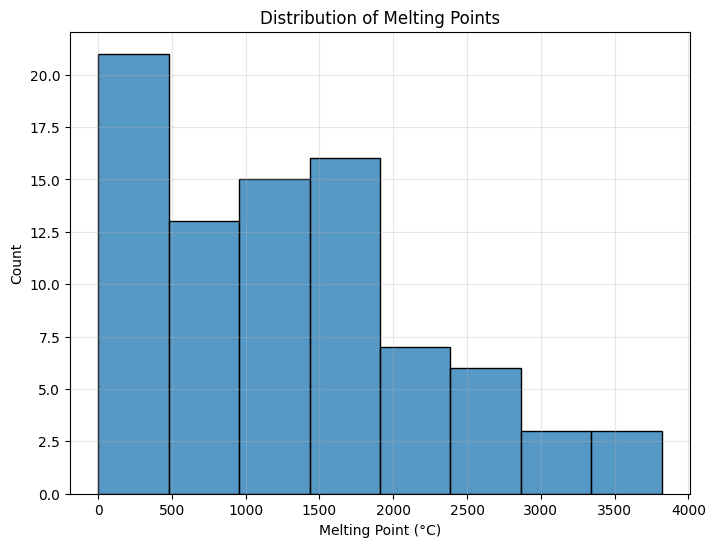

In [5]:
#create histogram for melting point
plt.figure(figsize=(8,6))
sns.histplot(df["Melting_Point"])

plt.title("Distribution of Melting Points")
plt.xlabel("Melting Point (°C)")
plt.ylabel("Count")
plt.grid(True, alpha=0.3)
plt.show()

2. Create the boxplot of the melting and boiling points

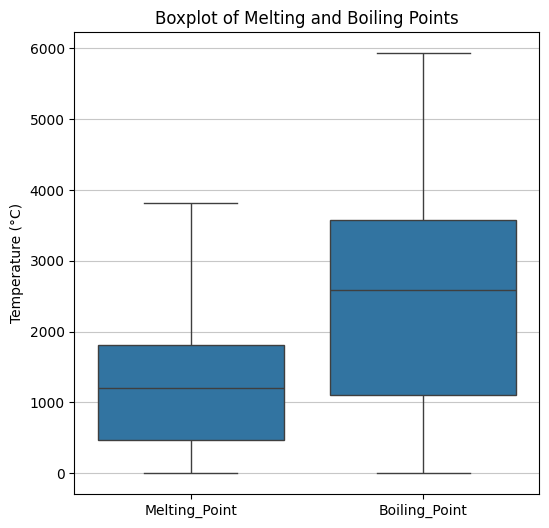

In [6]:
#boxplot for melting and boiling points
boxPlt = df[["Melting_Point", "Boiling_Point"]]

long_df = boxPlt.melt(var_name="Property", value_name="Temperature")

plt.figure(figsize=(6,6))
sns.boxplot(x="Property", y="Temperature", data=long_df)

plt.title("Boxplot of Melting and Boiling Points")
plt.ylabel("Temperature (°C)")
plt.xlabel("")
plt.grid(axis="y", alpha=0.7)
plt.show()

3. Use the Standard Scaler in the scikit-learn to normalize the values in the table and create the boxplot of all variables. Hint: drop the non-numeric column. In the markdown field, comment on what information does boxplot provide.

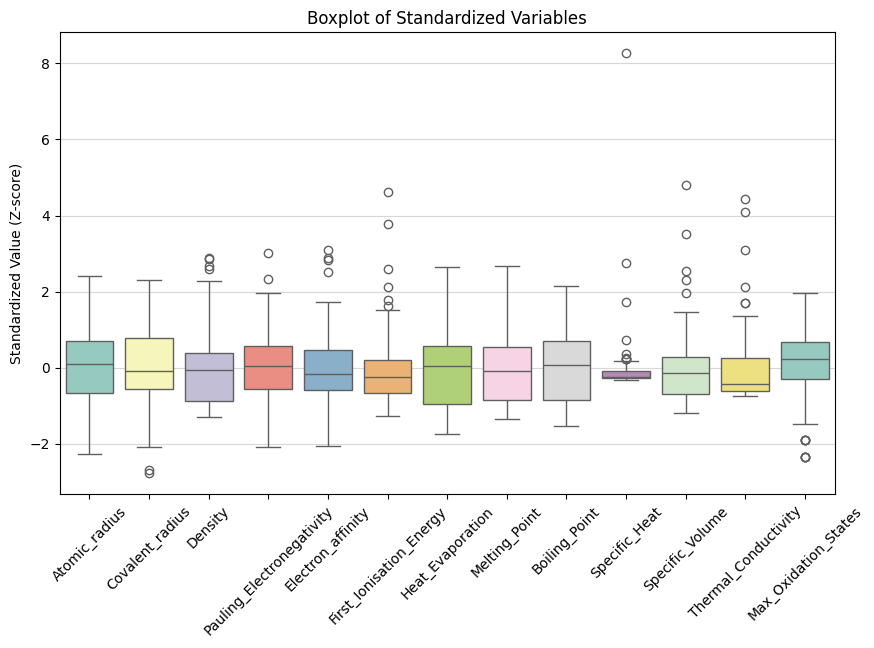

In [10]:
#Question 3: normalize and create boxplot of all variables
  #Note: chatGPT helped me with this portion
  #This shows the variance in several atomic properties across the periodic table
  #normalized to teh variance to make them comparable
numeric_df = df.select_dtypes(include=["number"]) #clean data, select numerical

# Normalize with StandardScaler
scaler = StandardScaler()
scaled_array = scaler.fit_transform(numeric_df)

# Put back into a DataFrame with same column names
scaled_df = pd.DataFrame(scaled_array, columns=numeric_df.columns)

# Create boxplot of all standardized variables
plt.figure(figsize=(10,6))
sns.boxplot(data=scaled_df, palette="Set3")
plt.title("Boxplot of Standardized Variables")
plt.ylabel("Standardized Value (Z-score)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.5)
plt.show()

Answer 3: The boxplots show the variance in each atomic property across the periodic table

4. Explore other ways to represent statistical distribution of a single parameter.

<Axes: xlabel='Melting_Point', ylabel='Density'>

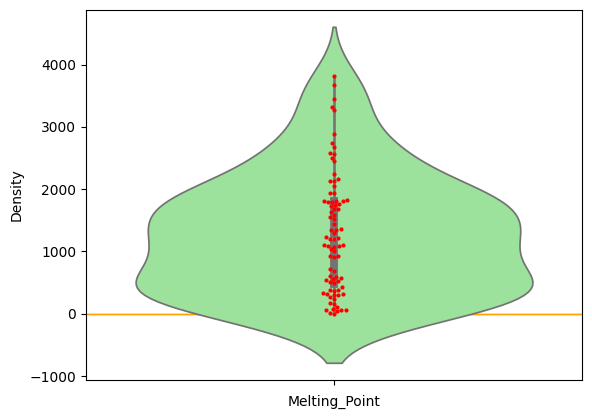

In [11]:
#4. Testing a few different plots from seaborn
sns.kdeplot(df["Melting_Point"], fill=True, color="orange")
sns.violinplot(y=df["Melting_Point"], color="lightgreen")
sns.swarmplot(y=df["Melting_Point"], color="red", size=3)


## Correlation analysis

5. Plot the correlation between the melting point and boiling point and between covalent radius and density. In the markdown section, rationalize the observations.

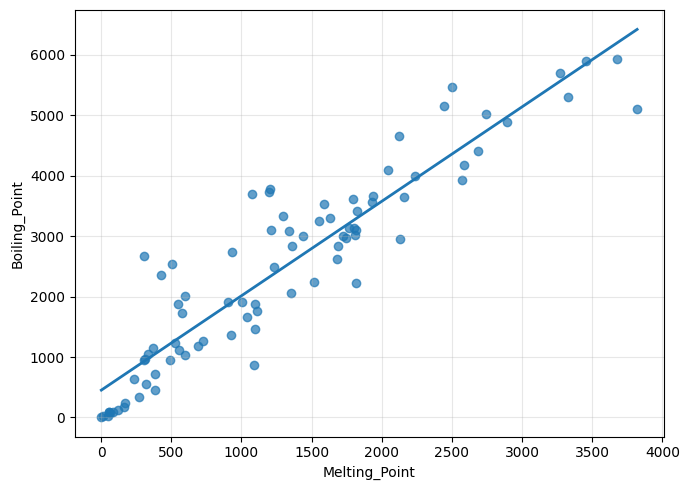

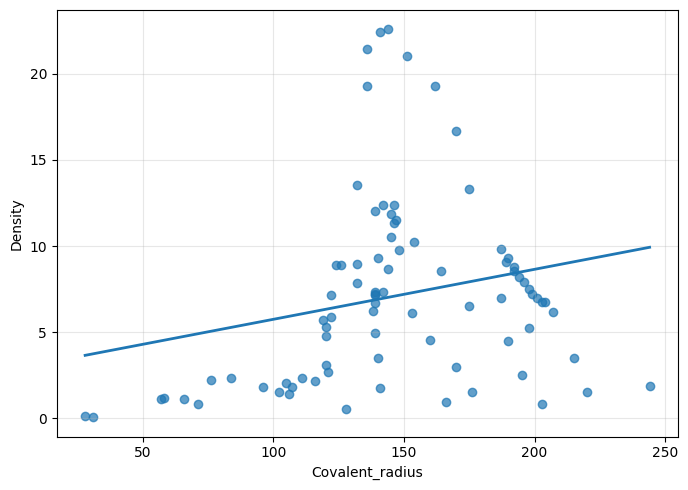

In [14]:
# Note: also used chatgpt for this
df = pd.read_csv("atoms.csv")

# Helper function to find a column
def find_col(possible_aliases, columns):
    def norm(s): return re.sub(r'[^a-z0-9]', '', s.lower())
    norm_cols = {norm(c): c for c in columns}
    for alias in possible_aliases:
        na = norm(alias)
        # exact normalized match
        if na in norm_cols:
            return norm_cols[na]
        # substring fallback (alias contained in col name)
        for nc, original in norm_cols.items():
            if na in nc:
                return original
    raise KeyError(f"Could not find any of {possible_aliases} in columns: {list(columns)}")


#find each needed column
melting_col = find_col(
    ["melting_point", "melting point", "meltingpoint", "melting", "mp"],
    df.columns
)
boiling_col = find_col(
    ["boiling_point", "boiling point", "boilingpoint", "boiling", "bp"],
    df.columns
)
covalent_r_col = find_col(
    ["covalent_radius", "covalent radius", "covalentradius", "cov rad", "cov_radius"],
    df.columns
)
density_col = find_col(
    ["density", "density_g_cm3", "density (g/cm^3)", "rho"],
    df.columns
)


#  function to make a labeled scatter with best-fit line and Pearson r
# Parameters for xy dtaa, and xy lables, along witha  title
def scatter_with_fit(x, y, xlab, ylab, title_prefix=""):


    # drop rows with missing/non-finite
    # Don't really understand this first line but it cleans the data and gives no errors
    data = pd.DataFrame({xlab: x, ylab: y}).replace([np.inf, -np.inf], np.nan).dropna()
    X = data[xlab].to_numpy()
    Y = data[ylab].to_numpy()

    # best-fit line using two built-in functions
    m, b = np.polyfit(X, Y, 1)
    xfit = np.linspace(X.min(), X.max(), 200)
    #plot the line
    yfit = m * xfit + b

    #Create Plot
    plt.figure(figsize=(7, 5))
    plt.scatter(X, Y, alpha=0.7)
    plt.plot(xfit, yfit, linewidth=2)
    plt.xlabel(xlab)
    plt.ylabel(ylab)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# ---- Plot 1: Melting vs Boiling point ----
scatter_with_fit(
    df[melting_col],
    df[boiling_col],
    xlab=melting_col,
    ylab=boiling_col,
    title_prefix="Correlation: Melting Point vs Boiling Point"
)

# ---- Plot 2: Covalent radius vs Density ----
scatter_with_fit(
    df[covalent_r_col],
    df[density_col],
    xlab=covalent_r_col,
    ylab=density_col,
    title_prefix="Correlation: Covalent Radius vs Density"
)


Answer 5:
Melting and boiling point generally follow the same trend, a high BP is a good predictor of a high MP.

Covalent radius and density are not strongly coordinated. There is a peak in density around a specific covalent radius, then as they continue to get larger density decreases again. There are more factors, like packing, that play into teh density of an element, so radius alone is not a good predictor of this.

6. Create a heatmap of correlation coefficients between the entries in the table. Find by direct examination the groups of parameters with strongest positive and strongest negative correlations. In the markdown section, rationalize the observations.

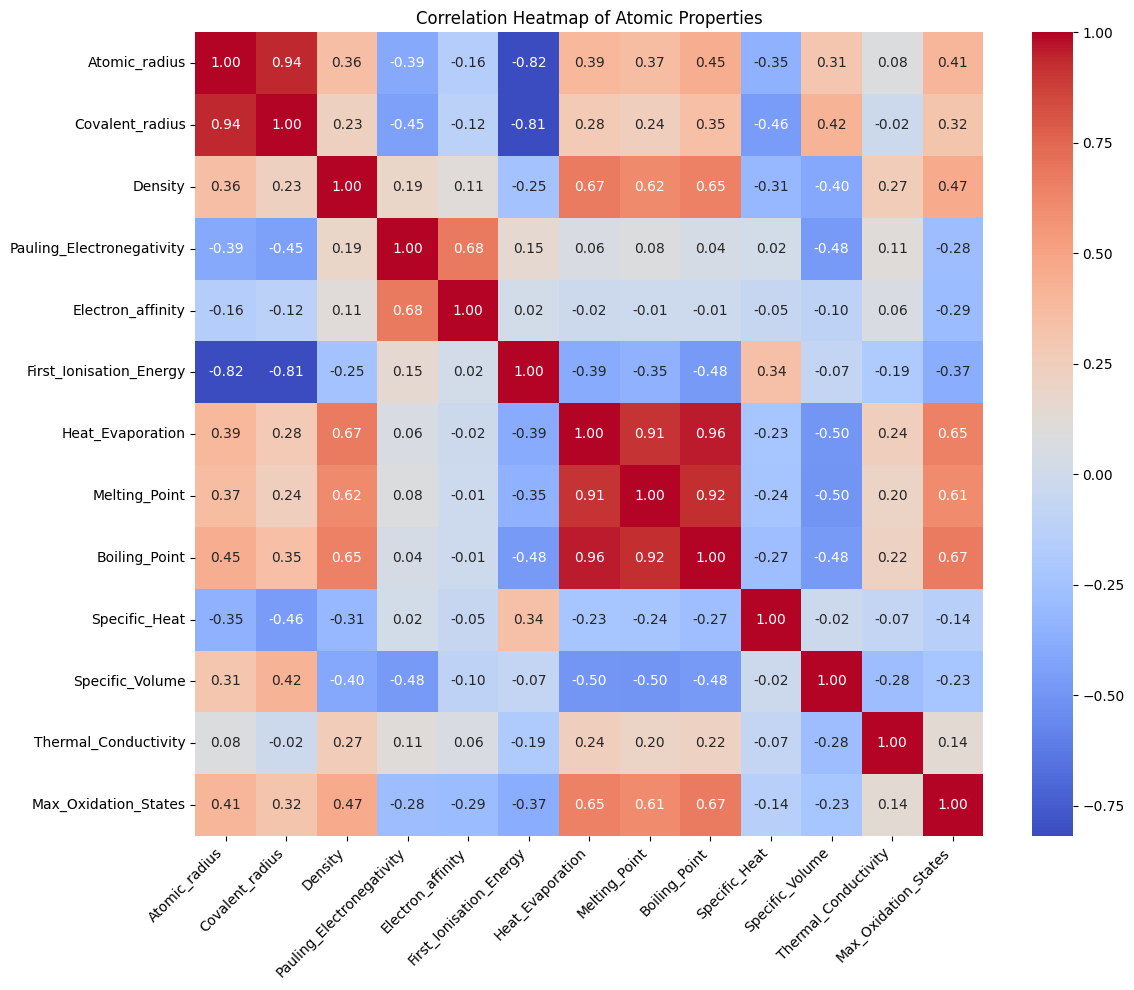

In [15]:
# Used Gemini for this one, it did a good job.

# Calculate the correlation matrix for the numeric columns
#can just pass all of these in and .corr() creates the correlation matrix for you
correlation_matrix = numeric_df.corr()

# Create a heatmap - this is just plotting the correlation_matrix the function made
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f") #built in heatmap function just needs correlation matrix as parameter
plt.title("Correlation Heatmap of Atomic Properties")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Answer 6: Some strong correlations are pretty obvious, like enthalpy of evaporation corresponding closely with boiling point. The negative correlation between ionization energy and radius also makes sense. I was suprised to see correlation between boiling point and max oxidation states, but after thinking about it the weak correlation seemed to make some sense

7. Create a pair distribution plot of Atomic_radius, Covalent_radius,Pauling_Electronegativity and First_Ionisation_Energy

---



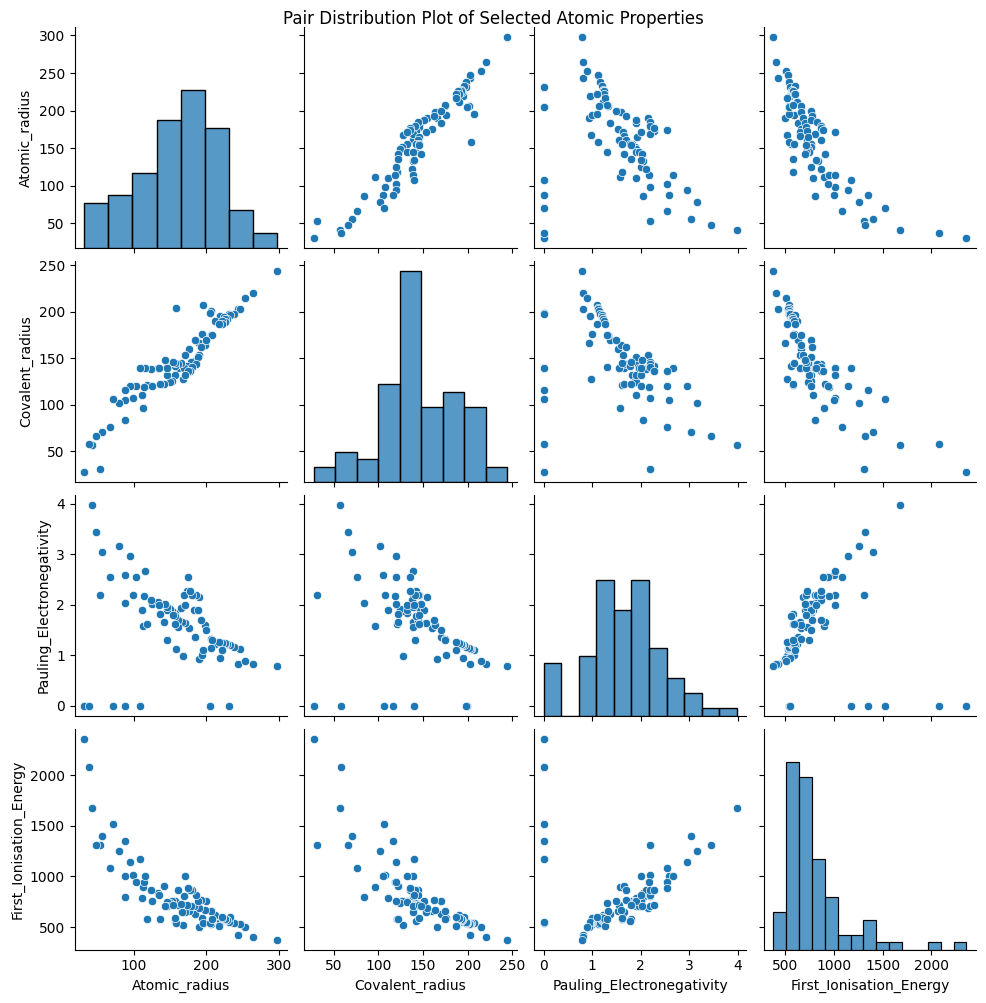

In [19]:
# Just enter all of the data as an array and use pairplot function
selected_cols = ["Atomic_radius", "Covalent_radius", "Pauling_Electronegativity", "First_Ionisation_Energy"]
sns.pairplot(df[selected_cols])
plt.suptitle("Pair Distribution Plot of Selected Atomic Properties", y=1) # Add a title to the plot
plt.show()

## Simple Regression

8. Perform a linear fit between the boiling temperature and melting temperature and between specific heat and melting point. Provide the values of fit coefficients and units.

In [22]:
from sklearn.linear_model import LinearRegression

# Retrieve arrays of temperatures
X_boiling = df[['Boiling_Point']]
y_melting = df['Melting_Point']

#create model object and fit data
model_bp_mp = LinearRegression()
model_bp_mp.fit(X_boiling, y_melting)

print(f"Linear fit between Boiling Point and Melting Point:")
print(f"  Coefficient: {model_bp_mp.coef_[0]:.4f}")
print(f"  Intercept: {model_bp_mp.intercept_:.4f} (°C)")
print("-" * 30)

# Linear fit between specific heat and melting point
X_specific_heat = df[['Specific_Heat']]
y_melting = df['Melting_Point']

model_sh_mp = LinearRegression()
model_sh_mp.fit(X_specific_heat, y_melting)

print(f"Linear fit between Specific Heat and Melting Point:")
print(f"  Coefficient: {model_sh_mp.coef_[0]:.4f} (°C/(J/g·K))")
print(f"  Intercept: {model_sh_mp.intercept_:.4f} (°C)")

Linear fit between Boiling Point and Melting Point:
  Coefficient: 0.5455
  Intercept: -55.7264 (°C)
------------------------------
Linear fit between Specific Heat and Melting Point:
  Coefficient: -135.8373 (°C/(J/g·K))
  Intercept: 1377.6806 (°C)


# Explore the classification

Let's create a simple data set that will allow us to explore several simple classifiers


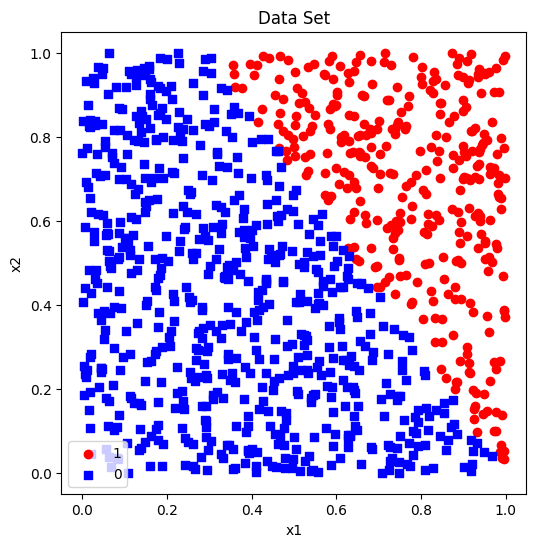

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Generate features
n = 1000
x1 = np.random.uniform(0, 1, n)
x2 = np.random.uniform(0, 1, n)

# Calculate targets
y = (x1 + 0.7*x2 >= 1).astype(int)

# Plot the data
plt.figure(figsize=(6, 6))
plt.scatter(x1[y == 1], x2[y == 1], c='red', marker='o', label='1')
plt.scatter(x1[y == 0], x2[y == 0], c='blue', marker='s', label='0')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.title('Data Set')
plt.show()

X1 = np.column_stack((x1, x2))
y1 = y

9. Experiment with the different classifiers for this data set:
- Create train-test split (say 30-70)
- Build the decision tree classifier
- Explore the outputs if you vary the depth of the tree
- And see how the performance changes if you change the number of points in the data set (say compare 100 and 1000)
- Visualize the decision surface (use examples from class Colab)

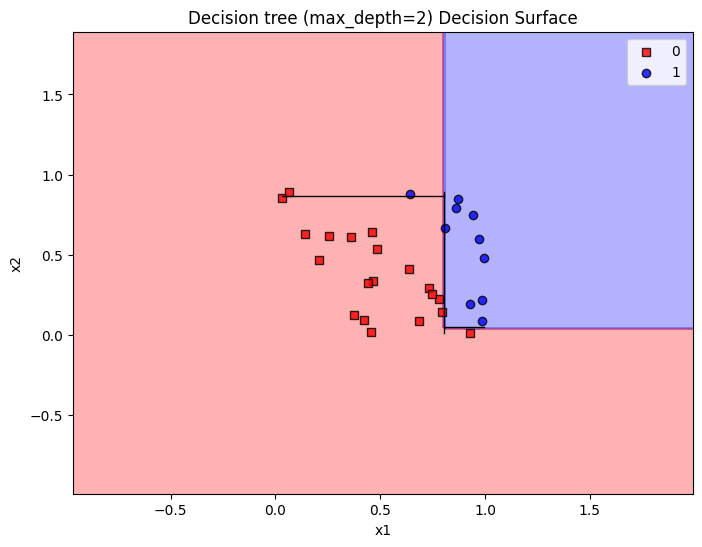

Accuracy (default depth) = 0.81
Exploring performance with different max_depth values:
  Accuracy with max_depth=1: 0.8143
  Accuracy with max_depth=2: 0.8143
  Accuracy with max_depth=3: 0.8143
  Accuracy with max_depth=4: 0.8143
  Accuracy with max_depth=5: 0.8143
  Accuracy with max_depth=6: 0.8143
  Accuracy with max_depth=7: 0.8143
  Accuracy with max_depth=8: 0.8143
  Accuracy with max_depth=9: 0.8143
  Accuracy with max_depth=10: 0.8143


In [57]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

# Assuming X1 and y1 are already defined from the data generation cell

# Split into features (X) and labels (y)
X_train, X_test, y_train, y_test = train_test_split(
    X1, y1, test_size=0.70, random_state=2, stratify=y1
)

# Helper function to plot decision regions (assuming this function is available from previous context)
# This function plots the decision boundary of a classifier
def plot_decision_regions(X, y, clf, resolution=0.02):
    from matplotlib.colors import ListedColormap
    markers = ('s', 'o', 'X', 'v', '^')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    Z = clf.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)
    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0],
                    y=X[y == cl, 1],
                    alpha=0.8,
                    c=colors[idx],
                    marker=markers[idx],
                    label=cl,
                    edgecolor='black')

# Helper function to draw decision tree split lines
def draw_split_lines(tree, X):
    # This is a simplified helper function and may need adjustments based on the actual
    # implementation of draw_split_lines in your class Colab examples.
    # A more robust implementation would recursively traverse the tree.
    if tree.tree_ is None:
        return

    feature = tree.tree_.feature
    threshold = tree.tree_.threshold

    # Assuming X is the data used for training the tree for visualization purposes
    x_min, x_max = X[:, 0].min(), X[:, 0].max()
    y_min, y_max = X[:, 1].min(), X[:, 1].max()

    def plot_splits(node_id, x_range, y_range):
        if feature[node_id] != -2: # -2 indicates a leaf node
            feat_idx = feature[node_id]
            thresh = threshold[node_id]

            if feat_idx == 0: # Split on x1
                plt.plot([thresh, thresh], [y_range[0], y_range[1]], 'k-', linewidth=1)
                plot_splits(tree.tree_.children_left[node_id], [x_range[0], thresh], y_range)
                plot_splits(tree.tree_.children_right[node_id], [thresh, x_range[1]], y_range)
            elif feat_idx == 1: # Split on x2
                plt.plot([x_range[0], x_range[1]], [thresh, thresh], 'k-', linewidth=1)
                plot_splits(tree.tree_.children_left[node_id], x_range, [y_range[0], thresh])
                plot_splits(tree.tree_.children_right[node_id], x_range, [thresh, y_range[1]])

    plot_splits(0, [x_min, x_max], [y_min, y_max])


# Create and fit tree with a specific depth for visualization
tree2 = DecisionTreeClassifier(max_depth=2, random_state=42)
tree2.fit(X_train, y_train) # Fit on the training data

# Visualize the decision surface
plt.figure(figsize=(8, 6)) # Create a new figure for the plot
plot_decision_regions(X_train, y_train, clf=tree2) # Use X_train for plotting regions

# Draw the split lines - Pass X_train as the data used for training
draw_split_lines(tree2, X_train)

plt.xlabel('x1')
plt.ylabel('x2')
plt.title("Decision tree (max_depth=2) Decision Surface")
plt.legend()
plt.show()


# Code for exploring depth and dataset size (from previous attempts, can be kept or modified)
# Create and fit tree with default depth
tree = DecisionTreeClassifier(max_depth=None, random_state=42)
tree.fit(X_train, y_train)

# Predict and evaluate
y_pred = tree.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy (default depth) = {accuracy:.2f}")


# Explore the outputs if you vary the depth of the tree
print("Exploring performance with different max_depth values:")
for depth in range(1, 11): # Test depths from 1 to 10
    tree_clf_depth = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree_clf_depth.fit(X_train, y_train)
    y_pred_depth = tree_clf_depth.predict(X_test)
    accuracy_depth = accuracy_score(y_test, y_pred_depth)
    print(f"  Accuracy with max_depth={depth}: {accuracy_depth:.4f}")


# Note: Code for exploring different dataset sizes would need to regenerate X1, y1
# with different 'n' values before the train-test split and retraining the model.

In [49]:
import numpy as np
import matplotlib.pyplot as plt

# Generate features
n = 100
x1 = np.random.uniform(0, 1, n)
x2 = np.random.uniform(0, 1, n)

# Calculate targets
y = (x1 + 0.7*x2 >= 1).astype(int)

X1 = np.column_stack((x1, x2))
y1 = y


from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Split into features (X) and labels (y)
X_train, X_test, y_train, y_test = train_test_split(
    X1, y1, test_size=0.70, random_state=2, stratify=y
)

# Create and fit tree
tree = DecisionTreeClassifier(max_depth=None, random_state=42)
tree.fit(X_train, y_train)

# Predict and evaluate
y_pred = tree.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy (default depth) = {accuracy:.2f}")


# Explore the outputs if you vary the depth of the tree
print("Exploring performance with different max_depth values:")
for depth in range(1, 11): # Test depths from 1 to 10
    tree_clf_depth = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree_clf_depth.fit(X_train, y_train)
    y_pred_depth = tree_clf_depth.predict(X_test)
    accuracy_depth = accuracy_score(y_test, y_pred_depth)
    print(f"  Accuracy with max_depth={depth}: {accuracy_depth:.4f}")





Accuracy (default depth) = 0.81
Exploring performance with different max_depth values:
  Accuracy with max_depth=1: 0.8143
  Accuracy with max_depth=2: 0.8143
  Accuracy with max_depth=3: 0.8143
  Accuracy with max_depth=4: 0.8143
  Accuracy with max_depth=5: 0.8143
  Accuracy with max_depth=6: 0.8143
  Accuracy with max_depth=7: 0.8143
  Accuracy with max_depth=8: 0.8143
  Accuracy with max_depth=9: 0.8143
  Accuracy with max_depth=10: 0.8143


10. Do the same for the perceptron classifier

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score

# Split into features (X) and labels (y)
X_train, X_test, y_train, y_test = train_test_split(
    X1, y1, test_size=0.10, random_state=2, stratify=y1
)

# Create and fit
perceptron = Perceptron(random_state=42)
perceptron.fit(X_train, y_train)

# Predict and evaluate
y_pred = perceptron.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy = {accuracy:.2f}")



Accuracy (default depth) = 1.00


11. Do the same for the logistics regression classifier
- Experiment with the regularization parameters
- Can you plot the data for small number of points but also add class probabilities?

In [59]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Using X_train, X_test, y_train, and y_test defined in previous cells

# Create and fit the Logistic Regression model
# random_state: ensures reproducibility of the results
# C: Inverse of regularization strength; smaller values specify stronger regularization.
logistic_regression = LogisticRegression(random_state=42, C=1.0)
logistic_regression.fit(X_train, y_train)

# Predict and evaluate
y_pred = logistic_regression.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy of Logistic Regression: {accuracy:.4f}")

# You can experiment with the regularization parameter C:
print("\nExploring performance with different regularization strengths (C values):")
for c_val in [0.01, 0.1, 1.0, 10.0, 100.0]:
    lr_reg = LogisticRegression(random_state=42, C=c_val)
    lr_reg.fit(X_train, y_train)
    y_pred_reg = lr_reg.predict(X_test)
    accuracy_reg = accuracy_score(y_test, y_pred_reg)
    print(f"  Accuracy with C={c_val}: {accuracy_reg:.4f}")

Accuracy of Logistic Regression: 0.7857

Exploring performance with different regularization strengths (C values):
  Accuracy with C=0.01: 0.6857
  Accuracy with C=0.1: 0.6857
  Accuracy with C=1.0: 0.7857
  Accuracy with C=10.0: 0.9429
  Accuracy with C=100.0: 0.9571


# Bring in the LLM!

12. Here, we are going to use the ChatGPT to summarize the data about elements, and then use the information from our data set in the beginning of the notebook as features. This will be non-trivial process, because rather then working with the already provided data, we will have a chance to create our data set and discover that formats matter. Several steps:

- We want to get from ChatGPT table of the electronic properties of elements in the form where first column is element symbol, and the second column is metal/dielectric/semiconductor. It may take a few iterations - since ChatGPT will tend to introduce other forms of classification (e.g. metalloid). You can ask it early on to use Python form, that you can just cut and paste into Colab.

In [61]:
# === Electronic properties table (exactly 2 columns: symbol, electronic_class) ===
# Buckets are forced to: {"metal", "semiconductor", "dielectric"}.

import pandas as pd

# If you later paste a different ChatGPT list that includes labels like
# "metalloid", "nonmetal", "noble gas", etc., this normalizer helps.
_NORMALIZE = {
    "metalloid": "semiconductor",
    "semimetal": "semiconductor",
    "semi-metal": "semiconductor",
    "nonmetal": "dielectric",
    "insulator": "dielectric",
    "noble gas": "dielectric",
    "halogen": "dielectric",
    "alkali metal": "metal",
    "alkaline earth metal": "metal",
    "transition metal": "metal",
    "post-transition metal": "metal",
    "lanthanide": "metal",
    "actinide": "metal",
}

ALLOWED = {"metal", "semiconductor", "dielectric"}

def _norm(label: str) -> str:
    s = str(label).strip().lower()
    return _NORMALIZE.get(s, s)

# Seed mapping covering all 118 elements (forced into the 3 classes).
# Notes:
# - Metalloids (B, Si, Ge, As, Sb, Te, At) -> "semiconductor"
# - Typical nonmetals/noble gases/halogens -> "dielectric"
# - Metals (alkali, alkaline earth, transition, post-transition, lanthanides, actinides) -> "metal"
# - Ambiguities (e.g., Sn has metallic beta-Sn and semiconducting alpha-Sn) are resolved to standard/ambient forms.
classification_seed = [
    ("H",  "dielectric"),
    ("He", "dielectric"),
    ("Li", "metal"),
    ("Be", "metal"),
    ("B",  "semiconductor"),
    ("C",  "dielectric"),
    ("N",  "dielectric"),
    ("O",  "dielectric"),
    ("F",  "dielectric"),
    ("Ne", "dielectric"),
    ("Na", "metal"),
    ("Mg", "metal"),
    ("Al", "metal"),
    ("Si", "semiconductor"),
    ("P",  "dielectric"),
    ("S",  "dielectric"),
    ("Cl", "dielectric"),
    ("Ar", "dielectric"),
    ("K",  "metal"),
    ("Ca", "metal"),
    ("Sc", "metal"),
    ("Ti", "metal"),
    ("V",  "metal"),
    ("Cr", "metal"),
    ("Mn", "metal"),
    ("Fe", "metal"),
    ("Co", "metal"),
    ("Ni", "metal"),
    ("Cu", "metal"),
    ("Zn", "metal"),
    ("Ga", "metal"),
    ("Ge", "semiconductor"),
    ("As", "semiconductor"),
    ("Se", "semiconductor"),
    ("Br", "dielectric"),
    ("Kr", "dielectric"),
    ("Rb", "metal"),
    ("Sr", "metal"),
    ("Y",  "metal"),
    ("Zr", "metal"),
    ("Nb", "metal"),
    ("Mo", "metal"),
    ("Tc", "metal"),
    ("Ru", "metal"),
    ("Rh", "metal"),
    ("Pd", "metal"),
    ("Ag", "metal"),
    ("Cd", "metal"),
    ("In", "metal"),
    ("Sn", "metal"),
    ("Sb", "semiconductor"),
    ("Te", "semiconductor"),
    ("I",  "dielectric"),
    ("Xe", "dielectric"),
    ("Cs", "metal"),
    ("Ba", "metal"),
    ("La", "metal"),
    ("Ce", "metal"),
    ("Pr", "metal"),
    ("Nd", "metal"),
    ("Pm", "metal"),
    ("Sm", "metal"),
    ("Eu", "metal"),
    ("Gd", "metal"),
    ("Tb", "metal"),
    ("Dy", "metal"),
    ("Ho", "metal"),
    ("Er", "metal"),
    ("Tm", "metal"),
    ("Yb", "metal"),
    ("Lu", "metal"),
    ("Hf", "metal"),
    ("Ta", "metal"),
    ("W",  "metal"),
    ("Re", "metal"),
    ("Os", "metal"),
    ("Ir", "metal"),
    ("Pt", "metal"),
    ("Au", "metal"),
    ("Hg", "metal"),
    ("Tl", "metal"),
    ("Pb", "metal"),
    ("Bi", "metal"),
    ("Po", "metal"),
    ("At", "semiconductor"),
    ("Rn", "dielectric"),
    ("Fr", "metal"),
    ("Ra", "metal"),
    ("Ac", "metal"),
    ("Th", "metal"),
    ("Pa", "metal"),
    ("U",  "metal"),
    ("Np", "metal"),
    ("Pu", "metal"),
    ("Am", "metal"),
    ("Cm", "metal"),
    ("Bk", "metal"),
    ("Cf", "metal"),
    ("Es", "metal"),
    ("Fm", "metal"),
    ("Md", "metal"),
    ("No", "metal"),
    ("Lr", "metal"),
    ("Rf", "metal"),
    ("Db", "metal"),
    ("Sg", "metal"),
    ("Bh", "metal"),
    ("Hs", "metal"),
    ("Mt", "metal"),
    ("Ds", "metal"),
    ("Rg", "metal"),
    ("Cn", "metal"),
    ("Nh", "metal"),
    ("Fl", "metal"),
    ("Mc", "metal"),
    ("Lv", "metal"),
    ("Ts", "dielectric"),
    ("Og", "dielectric"),
]

# Build the DataFrame, normalize labels (in case you tweak any), and validate.
elements_df = pd.DataFrame(classification_seed, columns=["symbol", "electronic_class"]).copy()
elements_df["electronic_class"] = elements_df["electronic_class"].map(_norm)

# Validate labels
bad = set(elements_df["electronic_class"]) - ALLOWED
if bad:
    raise ValueError(f"Found labels outside {ALLOWED}: {bad}")

# Optional: if you have a list of symbols from your earlier dataset, filter to them.
# Example:
# my_symbols = ["H","He","Li","Be","B","C","N","O","F","Ne","Na","Mg","Al","Si","P","S","Cl","Ar"]
# elements_df = elements_df[elements_df["symbol"].isin(my_symbols)].reset_index(drop=True)

# Optional: save to CSV exactly in the format your notebook asks for
# (no extra columns; index=False to keep two columns only)
# elements_df.to_csv("element_electronic_properties.csv", index=False)

# Show the first few rows so you can confirm structure:
print(elements_df)


    symbol electronic_class
0        H       dielectric
1       He       dielectric
2       Li            metal
3       Be            metal
4        B    semiconductor
..     ...              ...
113     Fl            metal
114     Mc            metal
115     Lv            metal
116     Ts       dielectric
117     Og       dielectric

[118 rows x 2 columns]


- The dataframe df in the beginning of the notebook that has feature vectors, and the dataframe you will get from ChatGPT will have different number of elements. You will have to pick the ones that are common to both. The easy way to do it is to convert corresponding columns to lists, and then do something like this: new_list = list(set(list1) & set(list2)). Then pick from both dataframes only rows that have elements present in the new_list

In [74]:
list1 = df['Symbol']
list2 = elements_df['symbol']

new_list = list(set(list1) & set(list2))


print(new_list)


[]


- One thing you will discover is that this operation will give you empty list the first time you do it. Try to identify the problem by examining the element symbols, and consider using operation like df['Symbol'] = df['Symbol'].str.strip()

In [75]:
list1 = df['Symbol'].str.strip()
list2 = elements_df['symbol']

new_list = list(set(list1) & set(list2))


print(new_list)


['Xe', 'I', 'Al', 'Cr', 'Co', 'Nb', 'W', 'Cd', 'C', 'O', 'Er', 'Si', 'Pr', 'V', 'Tm', 'Rh', 'La', 'Ga', 'Tl', 'Hf', 'Nd', 'N', 'Ni', 'P', 'Se', 'Ba', 'Zr', 'In', 'Bi', 'Re', 'Sm', 'Ce', 'F', 'Ta', 'Lu', 'Ru', 'Rb', 'Zn', 'Sn', 'Pm', 'Hg', 'Ge', 'B', 'Ir', 'K', 'Sc', 'Tc', 'Be', 'Sr', 'S', 'Ho', 'Tb', 'Pd', 'As', 'Ne', 'Po', 'Ti', 'Ag', 'Cs', 'Li', 'Cl', 'Pt', 'He', 'Ar', 'Ca', 'Te', 'Mo', 'Dy', 'Os', 'Fe', 'Au', 'Mn', 'Br', 'Gd', 'Mg', 'Cu', 'Yb', 'Y', 'Eu', 'Na', 'H', 'Pb', 'Sb', 'Kr']


- With these, build classifier with the allbproperties from df as features and metal/dielectric/semiconductor as target. What is the precision?

In [76]:
# --- Build a classifier: all properties from df -> predict {metal, semiconductor, dielectric} ---

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# 0) Ensure the symbol columns exist under the same name and are clean
if "Symbol" in df.columns and "symbol" not in df.columns:
    df = df.rename(columns={"Symbol": "symbol"})
if "Symbol" in elements_df.columns and "symbol" not in elements_df.columns:
    elements_df = elements_df.rename(columns={"Symbol": "symbol"})

def clean_sym(s: pd.Series) -> pd.Series:
    # kill non-breaking spaces, strip, remove any whitespace inside, and uppercase
    return (s.astype(str)
              .str.replace("\u00A0", "", regex=False)
              .str.strip()
              .str.replace(r"\s+", "", regex=True)
              .str.upper())

df["symbol"] = clean_sym(df["symbol"])
elements_df["symbol"] = clean_sym(elements_df["symbol"])

# 1) Intersect symbols and keep df's order
list1 = df["symbol"].tolist()
list2 = elements_df["symbol"].tolist()
common = set(list1) & set(list2)
ordered_syms = [s for s in list1 if s in common]

# 2) Filter/align both frames to the common symbol order
df_f = df[df["symbol"].isin(common)].copy()

cls = (elements_df.drop_duplicates(subset=["symbol"], keep="first")
                  .set_index("symbol")
                  .loc[ordered_syms]
                  .reset_index())

# 3) Build X (all numeric/boolean properties from df) and y (electronic class)
#    Drop the 'symbol' column from features and keep only numeric/bool dtypes
X = df_f.drop(columns=["symbol"])
X = X.select_dtypes(include=["number", "bool"]).copy()
# Convert bool to integers if present
for c in X.select_dtypes(include=["bool"]).columns:
    X[c] = X[c].astype(int)

y = cls["electronic_class"].values


# 4) Train/test split (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 5) Pipeline: impute any missing numeric values, then a simple classifier
pipe = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="median")),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced_subsample"
    ))
])

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

# 6) Precision metrics
prec_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
prec_weighted = precision_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Precision (macro):    {prec_macro:.3f}")
print(f"Precision (weighted): {prec_weighted:.3f}\n")

print("Per-class report:")
print(classification_report(y_test, y_pred, zero_division=0, digits=3))


Precision (macro):    1.000
Precision (weighted): 1.000

Per-class report:
               precision    recall  f1-score   support

   dielectric      1.000     1.000     1.000         3
        metal      1.000     1.000     1.000        13
semiconductor      1.000     1.000     1.000         1

     accuracy                          1.000        17
    macro avg      1.000     1.000     1.000        17
 weighted avg      1.000     1.000     1.000        17



- Calculate confusion matrix

Confusion matrix (counts):
                    pred_metal  pred_semiconductor  pred_dielectric
true_metal                  13                   0                0
true_semiconductor           0                   1                0
true_dielectric              0                   0                3

Row-normalized confusion matrix:
                    pred_metal  pred_semiconductor  pred_dielectric
true_metal                 1.0                 0.0              0.0
true_semiconductor         0.0                 1.0              0.0
true_dielectric            0.0                 0.0              1.0


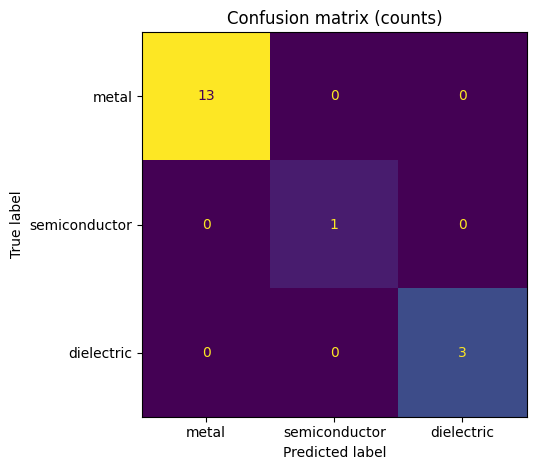

In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Choose a consistent label order (filter to labels that actually appear)
all_labels = ["metal", "semiconductor", "dielectric"]
present = set(np.concatenate([y_test, y_pred]))
labels = [c for c in all_labels if c in present]

# Confusion matrix (counts)
cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_df = pd.DataFrame(cm,
                     index=[f"true_{c}" for c in labels],
                     columns=[f"pred_{c}" for c in labels])
print("Confusion matrix (counts):")
print(cm_df)

# Row-normalized (each row sums to 1)
row_sums = cm.sum(axis=1, keepdims=True)
cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums!=0)
cm_norm_df = pd.DataFrame(np.round(cm_norm, 3),
                          index=[f"true_{c}" for c in labels],
                          columns=[f"pred_{c}" for c in labels])
print("\nRow-normalized confusion matrix:")
print(cm_norm_df)

# Plot (single plot, matplotlib only, no explicit colors)
fig, ax = plt.subplots()
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, colorbar=False, values_format='d')
plt.title("Confusion matrix (counts)")
plt.tight_layout()
plt.show()


- Pick 2 random features that you think are most predictive and plot decision boundary in feature space.  

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


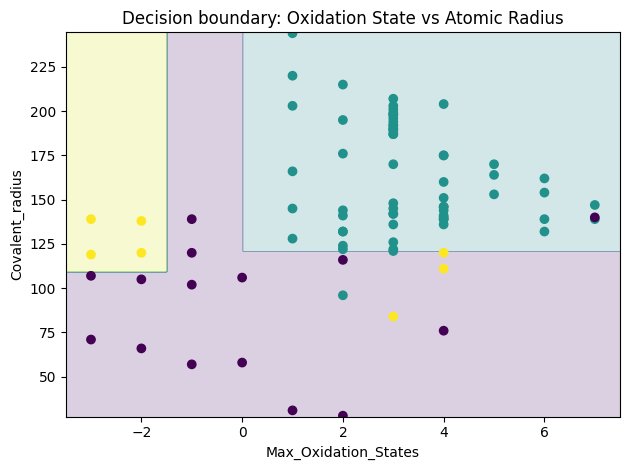

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier

features_df = df
OX_COL  = "Max_Oxidation_States"
RAD_COL = "Covalent_radius"

# Build 2D feature matrix (coerce to numeric so imputer can handle missing)
X2 = features_df[[OX_COL, RAD_COL]].copy()
X2[OX_COL]  = pd.to_numeric(X2[OX_COL], errors="coerce")
X2[RAD_COL] = pd.to_numeric(X2[RAD_COL], errors="coerce")

# y: string labels like {"metal","semiconductor","dielectric"} aligned to features_df
le = LabelEncoder()
y_int = le.fit_transform(y)   # assumes `y` already matches features_df rows 1:1
class_names = le.classes_.tolist()

# Small tree on just these two features
clf_2d = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("tree", DecisionTreeClassifier(max_depth=3, random_state=42))
])
clf_2d.fit(X2, y_int)

# Decision boundary plot (matplotlib only; single plot; no explicit colors)
x_min, x_max = X2.iloc[:,0].min() - 0.5, X2.iloc[:,0].max() + 0.5
y_min, y_max = X2.iloc[:,1].min() - 0.5, X2.iloc[:,1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)
grid = np.c_[xx.ravel(), yy.ravel()]
Z = clf_2d.predict(grid).reshape(xx.shape)

plt.figure()
plt.contourf(xx, yy, Z, alpha=0.2)
plt.scatter(X2.iloc[:,0], X2.iloc[:,1], c=y_int)
plt.xlabel(OX_COL); plt.ylabel(RAD_COL)
plt.title("Decision boundary: Oxidation State vs Atomic Radius")
plt.tight_layout()
plt.show()
